<a href="https://colab.research.google.com/github/lmthanh159/customer-churn-prediction-pyspark/blob/main/IBM_Telco_Churn_PySpark_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CUSTOMER CHURN PREDICTION USING PYSPARK ON GOOGLE COLAB

## Môn học
Công nghệ Big Data

## Đề tài
Xây dựng hệ thống dự đoán khách hàng rời bỏ dịch vụ bằng PySpark trên Google Colab

## Bộ dữ liệu
IBM Telco Customer Churn

## Mục tiêu
- Tiền xử lý dữ liệu khách hàng bằng PySpark
- Phân tích dữ liệu bằng SparkSQL
- Xây dựng mô hình dự đoán churn bằng Spark ML
- So sánh hiệu năng nhiều mô hình
- Chọn mô hình tốt nhất


# 1. Environment Setup

Cài đặt PySpark và khởi tạo `SparkSession`.


In [ ]:
!pip -q install pyspark

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("IBM_Telco_Customer_Churn_Prediction")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

print("Spark version:", spark.version)
spark.range(5).show()

Spark version: 4.0.2
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



# 2. Import Libraries

In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import (
    LogisticRegression,
    DecisionTreeClassifier,
    RandomForestClassifier,
    GBTClassifier,
    MultilayerPerceptronClassifier,
    LinearSVC,
    NaiveBayes,
    OneVsRest
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

# 3. Upload Dataset


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("Đã kết nối Google Drive thành công.")

Mounted at /content/drive
Đã kết nối Google Drive thành công.


In [ ]:
COMMON_FILES = [
    "/content/drive/MyDrive/Colab Notebooks/Churn_Prediction/Telco-Customer-Churn.csv"
]

DATA_PATH = None
for f in COMMON_FILES:
    if os.path.exists(f):
        DATA_PATH = f
        break

if DATA_PATH is None:
    uploaded = files.upload()
    for name in uploaded.keys():
        if name.endswith(".csv"):
            DATA_PATH = f"/content/drive/MyDrive/Colab Notebooks/Churn_Prediction/{name}"
            break

if DATA_PATH is None:
    raise FileNotFoundError("Không tìm thấy file CSV của IBM Telco Customer Churn trong /content.")

print("Using DATA_PATH =", DATA_PATH)

Using DATA_PATH = /content/drive/MyDrive/Colab Notebooks/Churn_Prediction/Telco-Customer-Churn.csv


# 4. Load Dataset

In [ ]:
raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(DATA_PATH)
)

print("Rows:", raw_df.count())
print("Columns:", len(raw_df.columns))
raw_df.show(5, truncate=False)
raw_df.printSchema()

Rows: 7043
Columns: 21
+----------+------+-------------+-------+----------+------+------------+----------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------------+----------------+-------------------------+--------------+------------+-----+
|customerID|gender|SeniorCitizen|Partner|Dependents|tenure|PhoneService|MultipleLines   |InternetService|OnlineSecurity|OnlineBackup|DeviceProtection|TechSupport|StreamingTV|StreamingMovies|Contract      |PaperlessBilling|PaymentMethod            |MonthlyCharges|TotalCharges|Churn|
+----------+------+-------------+-------+----------+------+------------+----------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------------+----------------+-------------------------+--------------+------------+-----+
|7590-VHVEG|Female|0            |Yes    |No        |1     |No          |No phone service|DSL            |No            |Yes     

# 5. Initial Data Inspection

In [ ]:
# Kiểm tra null / rỗng theo từng cột
null_df = raw_df.select([
    F.count(F.when(F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""), c)).alias(c)
    for c in raw_df.columns
])
null_df.show(truncate=False)

# Kiểm tra trùng customerID
dup_count = raw_df.groupBy("customerID").count().filter(F.col("count") > 1).count()
print("Duplicate customerID count:", dup_count)

# Phân bố nhãn Churn
raw_df.groupBy("Churn").count().show()

+----------+------+-------------+-------+----------+------+------------+-------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------+----------------+-------------+--------------+------------+-----+
|customerID|gender|SeniorCitizen|Partner|Dependents|tenure|PhoneService|MultipleLines|InternetService|OnlineSecurity|OnlineBackup|DeviceProtection|TechSupport|StreamingTV|StreamingMovies|Contract|PaperlessBilling|PaymentMethod|MonthlyCharges|TotalCharges|Churn|
+----------+------+-------------+-------+----------+------+------------+-------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------+----------------+-------------+--------------+------------+-----+
|0         |0     |0            |0      |0         |0     |0           |0            |0              |0             |0           |0               |0          |0          |0              |0       |0               |0

# 6. Data Cleaning

Các bước làm sạch chính:
- Chuẩn hóa `TotalCharges` về số thực
- Tạo cột nhãn `label` từ `Churn`
- Loại bỏ các dòng không hợp lệ ở `TotalCharges`
- Giữ `SeniorCitizen` là biến số


In [ ]:
df = raw_df.withColumn(
    "TotalCharges",
    F.when(F.trim(F.col("TotalCharges").cast("string")) == "", None)
     .otherwise(F.col("TotalCharges").cast(DoubleType()))
)

df = df.withColumn(
    "label",
    F.when(F.col("Churn") == "Yes", F.lit(1.0)).otherwise(F.lit(0.0))
)

# Loại các dòng không có TotalCharges
df = df.na.drop(subset=["TotalCharges"])

print("Rows after cleaning:", df.count())
df.select("customerID", "MonthlyCharges", "TotalCharges", "Churn", "label").show(5, truncate=False)

Rows after cleaning: 7032
+----------+--------------+------------+-----+-----+
|customerID|MonthlyCharges|TotalCharges|Churn|label|
+----------+--------------+------------+-----+-----+
|7590-VHVEG|29.85         |29.85       |No   |0.0  |
|5575-GNVDE|56.95         |1889.5      |No   |0.0  |
|3668-QPYBK|53.85         |108.15      |Yes  |1.0  |
|7795-CFOCW|42.3          |1840.75     |No   |0.0  |
|9237-HQITU|70.7          |151.65      |Yes  |1.0  |
+----------+--------------+------------+-----+-----+
only showing top 5 rows


In [ ]:
# Kiểm tra lại null sau khi làm sạch
df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns
]).show(truncate=False)

+----------+------+-------------+-------+----------+------+------------+-------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------+----------------+-------------+--------------+------------+-----+-----+
|customerID|gender|SeniorCitizen|Partner|Dependents|tenure|PhoneService|MultipleLines|InternetService|OnlineSecurity|OnlineBackup|DeviceProtection|TechSupport|StreamingTV|StreamingMovies|Contract|PaperlessBilling|PaymentMethod|MonthlyCharges|TotalCharges|Churn|label|
+----------+------+-------------+-------+----------+------+------------+-------------+---------------+--------------+------------+----------------+-----------+-----------+---------------+--------+----------------+-------------+--------------+------------+-----+-----+
|0         |0     |0            |0      |0         |0     |0           |0            |0              |0             |0           |0               |0          |0          |0              |0       |

# 7. Exploratory Data Analysis with SparkSQL

In [ ]:
df.createOrReplaceTempView("telco")

In [ ]:
# Tỷ lệ churn tổng thể
result = df.groupBy("Churn") \
    .agg(F.count("*").alias("total_customers")) \
    .withColumn("percentage", F.round(F.col("total_customers") * 100.0 / F.sum("total_customers").over(Window.partitionBy()), 2)) \
    .orderBy("Churn")

result.show()

+-----+---------------+----------+
|Churn|total_customers|percentage|
+-----+---------------+----------+
|   No|           5163|     73.42|
|  Yes|           1869|     26.58|
+-----+---------------+----------+



In [ ]:
# Churn theo loại hợp đồng
contract_churn_pivot = df.groupBy("Contract") \
    .pivot("Churn") \
    .count() \
    .fillna(0) # Thay thế giá trị null bằng 0 nếu có

contract_churn_pivot.show()

+--------------+----+----+
|      Contract|  No| Yes|
+--------------+----+----+
|      Two year|1637|  48|
|      One year|1306| 166|
|Month-to-month|2220|1655|
+--------------+----+----+



In [ ]:
# Churn rate theo loại hợp đồng
contract_analysis = df.groupBy("Contract") \
    .agg(
        F.round(F.avg("label") * 100, 2).alias("churn_rate_percent"),
        F.count("*").alias("total_customers")
    ) \
    .orderBy(F.col("churn_rate_percent").desc())

# Hiển thị kết quả
contract_analysis.show()

+--------------+------------------+---------------+
|      Contract|churn_rate_percent|total_customers|
+--------------+------------------+---------------+
|Month-to-month|             42.71|           3875|
|      One year|             11.28|           1472|
|      Two year|              2.85|           1685|
+--------------+------------------+---------------+



In [ ]:
# Churn rate theo phương thức thanh toán
payment_churn_analysis = df.groupBy("PaymentMethod") \
    .agg(
        F.round(F.avg("label") * 100, 2).alias("churn_rate_percent"),
        F.count("*").alias("total_customers")
    ) \
    .orderBy(F.col("churn_rate_percent").desc())

# Hiển thị kết quả
payment_churn_analysis.show(truncate=False)

+-------------------------+------------------+---------------+
|PaymentMethod            |churn_rate_percent|total_customers|
+-------------------------+------------------+---------------+
|Electronic check         |45.29             |2365           |
|Mailed check             |19.2              |1604           |
|Bank transfer (automatic)|16.73             |1542           |
|Credit card (automatic)  |15.25             |1521           |
+-------------------------+------------------+---------------+



In [ ]:
# Thống kê mô tả các cột số
df.select("tenure", "MonthlyCharges", "TotalCharges").describe().show()

+-------+------------------+------------------+------------------+
|summary|            tenure|    MonthlyCharges|      TotalCharges|
+-------+------------------+------------------+------------------+
|  count|              7032|              7032|              7032|
|   mean|32.421786120591584| 64.79820819112632|2283.3004408418697|
| stddev|24.545259709263245|30.085973884049825| 2266.771361883145|
|    min|                 1|             18.25|              18.8|
|    max|                72|            118.75|            8684.8|
+-------+------------------+------------------+------------------+



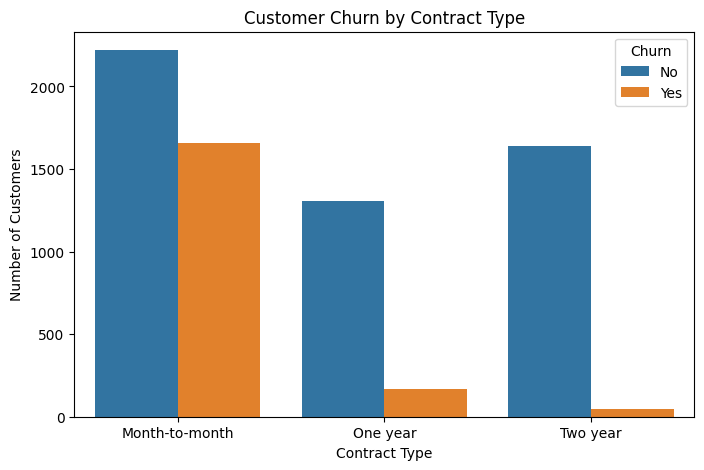

In [ ]:
# Trực quan hóa: churn theo loại hợp đồng
contract_pd = df.groupBy("Contract", "Churn") \
    .agg(F.count("*").alias("total")) \
    .orderBy("Contract", "Churn") \
    .toPandas()

plt.figure(figsize=(8, 5))
sns.barplot(data=contract_pd, x='Contract', y='total', hue='Churn')

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

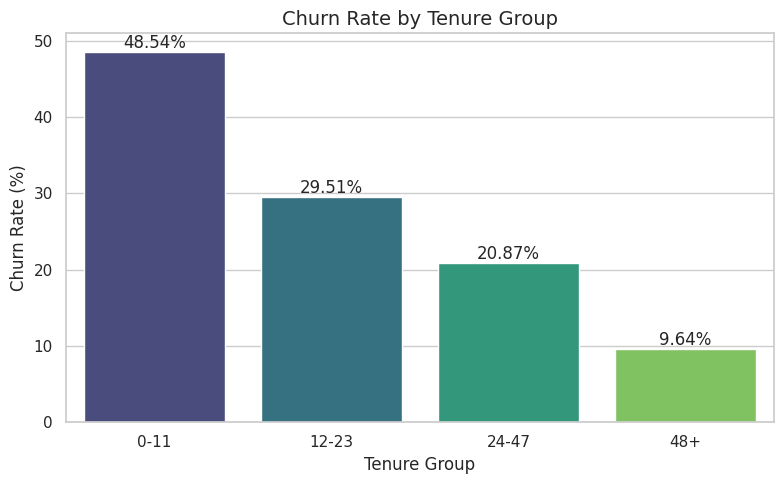

In [ ]:
# Trực quan hóa: churn rate theo tenure group
tenure_group_df = df.withColumn(
    "tenure_group",
    F.when(F.col("tenure") < 12, "0-11")
     .when((F.col("tenure") >= 12) & (F.col("tenure") < 24), "12-23")
     .when((F.col("tenure") >= 24) & (F.col("tenure") < 48), "24-47")
     .otherwise("48+")
)

tenure_group_df.createOrReplaceTempView("telco_tenure")

# 1. Xử lý dữ liệu bằng PySpark DataFrame API
tenure_pd = tenure_group_df.groupBy("tenure_group") \
    .agg(F.round(F.avg("label") * 100, 2).alias("churn_rate_percent")) \
    .orderBy("tenure_group") \
    .toPandas()

# 2. Trực quan hóa bằng Seaborn
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Vẽ biểu đồ cột
ax = sns.barplot(
    data=tenure_pd,
    x="tenure_group",
    y="churn_rate_percent",
    palette="viridis"
)

plt.title("Churn Rate by Tenure Group", fontsize=14)
plt.xlabel("Tenure Group", fontsize=12)
plt.ylabel("Churn Rate (%)", fontsize=12)

# Hiển thị giá trị trên tất cả các cột
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.tight_layout()
plt.show()

# 8. Feature Selection

Loại bỏ:
- `customerID`: cột định danh
- `Churn`: nhãn gốc dạng chuỗi

Giữ:
- `label`: nhãn số
- tất cả các cột còn lại làm đặc trưng


In [ ]:
ID_COL = "customerID"
TARGET_COL = "label"

feature_df = df.drop("customerID", "Churn")

categorical_cols = [c for c, t in feature_df.dtypes if t == "string" and c != TARGET_COL]
numeric_cols = [c for c, t in feature_df.dtypes if t in ["int", "bigint", "double", "float"] and c != TARGET_COL]

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)
print("Total categorical:", len(categorical_cols))
print("Total numeric:", len(numeric_cols))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Total categorical: 15
Total numeric: 4


# 9. Train/Test Split

In [ ]:
TRAIN_RATIO = 0.8
TEST_RATIO = 0.2
SEED = 42

train_df, test_df = feature_df.randomSplit([TRAIN_RATIO, TEST_RATIO], seed=SEED)

print("Train rows:", train_df.count())
print("Test rows:", test_df.count())

train_df.groupBy("label").count().show()
test_df.groupBy("label").count().show()

Train rows: 5690
Test rows: 1342
+-----+-----+
|label|count|
+-----+-----+
|  1.0| 1526|
|  0.0| 4164|
+-----+-----+

+-----+-----+
|label|count|
+-----+-----+
|  1.0|  343|
|  0.0|  999|
+-----+-----+



# 10. Build Preprocessing Stages

Pipeline tiền xử lý:
- `StringIndexer`
- `OneHotEncoder`
- `VectorAssembler`


In [ ]:
indexers = [
    StringIndexer(inputCol=col, outputCol=f"{col}_idx", handleInvalid="keep")
    for col in categorical_cols
]

encoders = [
    OneHotEncoder(inputCol=f"{col}_idx", outputCol=f"{col}_ohe")
    for col in categorical_cols
]

assembler_inputs = [f"{col}_ohe" for col in categorical_cols] + numeric_cols

assembler = VectorAssembler(
    inputCols=assembler_inputs,
    outputCol="features",
    handleInvalid="keep"
)

preprocess_stages = indexers + encoders + [assembler]

# 11. Evaluation Utilities

In [ ]:
def evaluate_predictions(pred_df, model_name):
    multiclass_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction")
    binary_eval = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

    metrics = {
        "model": model_name,
        "accuracy": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy").evaluate(pred_df),
        "precision": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedPrecision").evaluate(pred_df),
        "recall": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="weightedRecall").evaluate(pred_df),
        "f1": MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1").evaluate(pred_df),
        "auc": binary_eval.evaluate(pred_df)
    }
    return metrics

def show_confusion_matrix(pred_df):
    cm = (
        pred_df.groupBy("label")
        .pivot("prediction")
        .count()
        .fillna(0)
        .orderBy("label")
    )
    cm.show()

model_results = []

# 12.1. Model 1 - Logistic Regression

In [ ]:
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.0,
    elasticNetParam=0.0
)

lr_pipeline = Pipeline(stages=preprocess_stages + [lr])
lr_model = lr_pipeline.fit(train_df)
lr_pred = lr_model.transform(test_df)

lr_pred.select("label", "prediction", "probability").show(5, truncate=False)
lr_metrics = evaluate_predictions(lr_pred, "Logistic Regression")
model_results.append(lr_metrics)
lr_metrics

+-----+----------+---------------------------------------+
|label|prediction|probability                            |
+-----+----------+---------------------------------------+
|0.0  |1.0       |[0.41564762164478897,0.584352378355211]|
|1.0  |1.0       |[0.4033908682960658,0.5966091317039341]|
|0.0  |0.0       |[0.6793571343059387,0.3206428656940613]|
|0.0  |0.0       |[0.5996408112791638,0.4003591887208362]|
|1.0  |0.0       |[0.567676397134966,0.432323602865034]  |
+-----+----------+---------------------------------------+
only showing top 5 rows


{'model': 'Logistic Regression',
 'accuracy': 0.8107302533532041,
 'precision': 0.803400383062037,
 'recall': 0.8107302533532043,
 'f1': 0.8058305612567758,
 'auc': 0.858129266292533}

### Nhận xét
Logistic Regression là baseline mạnh cho bài toán churn vì dễ diễn giải và chạy nhanh.


# 12.2. Model 2 - Decision Tree

In [ ]:
dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=5,
    seed=SEED
)

dt_pipeline = Pipeline(stages=preprocess_stages + [dt])
dt_model = dt_pipeline.fit(train_df)
dt_pred = dt_model.transform(test_df)

dt_metrics = evaluate_predictions(dt_pred, "Decision Tree")
model_results.append(dt_metrics)
dt_metrics

{'model': 'Decision Tree',
 'accuracy': 0.7906110283159463,
 'precision': 0.7779192323183168,
 'recall': 0.7906110283159464,
 'f1': 0.7809673426356949,
 'auc': 0.7509025060045467}

# 12.3. Model 3 - Random Forest

In [ ]:
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=8,
    seed=SEED
)

rf_pipeline = Pipeline(stages=preprocess_stages + [rf])
rf_model = rf_pipeline.fit(train_df)
rf_pred = rf_model.transform(test_df)

rf_metrics = evaluate_predictions(rf_pred, "Random Forest")
model_results.append(rf_metrics)
rf_metrics

{'model': 'Random Forest',
 'accuracy': 0.8077496274217586,
 'precision': 0.7954991855337346,
 'recall': 0.8077496274217586,
 'f1': 0.7953285741223446,
 'auc': 0.8582708072503995}

# 12.4. Model 4 - GBT Classifier

`GBTClassifier` trong Spark chỉ hỗ trợ nhãn nhị phân, nên phù hợp với bài toán churn.


In [ ]:
gbt = GBTClassifier(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    maxDepth=5,
    seed=SEED
)

gbt_pipeline = Pipeline(stages=preprocess_stages + [gbt])
gbt_model = gbt_pipeline.fit(train_df)
gbt_pred = gbt_model.transform(test_df)

gbt_metrics = evaluate_predictions(gbt_pred, "GBT Classifier")
model_results.append(gbt_metrics)
gbt_metrics

{'model': 'GBT Classifier',
 'accuracy': 0.8002980625931445,
 'precision': 0.7910400600547964,
 'recall': 0.8002980625931445,
 'f1': 0.7938929653231591,
 'auc': 0.8435768129645734}

# 12.5. Model 5 - Multilayer Perceptron Classifier

In [ ]:
temp_pipeline = Pipeline(stages=preprocess_stages)
temp_model = temp_pipeline.fit(train_df)
transformed_train = temp_model.transform(train_df)
input_dim = len(transformed_train.select("features").first()["features"])

layers = [input_dim, 32, 16, 2]

mlp = MultilayerPerceptronClassifier(
    featuresCol="features",
    labelCol="label",
    layers=layers,
    maxIter=100,
    seed=SEED
)

mlp_pipeline = Pipeline(stages=preprocess_stages + [mlp])
mlp_model = mlp_pipeline.fit(train_df)
mlp_pred = mlp_model.transform(test_df)

mlp_metrics = evaluate_predictions(mlp_pred, "Multilayer Perceptron Classifier")
model_results.append(mlp_metrics)
mlp_metrics

{'model': 'Multilayer Perceptron Classifier',
 'accuracy': 0.7622950819672131,
 'precision': 0.7403630611700509,
 'recall': 0.7622950819672132,
 'f1': 0.7444309925134385,
 'auc': 0.80090878050062}

# 12.6. Model 6 - Linear SVM (LinearSVC)

In [ ]:
from pyspark.ml.classification import LinearSVC

lsvc = LinearSVC(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    regParam=0.1
)

lsvc_pipeline = Pipeline(stages=preprocess_stages + [lsvc])
lsvc_model = lsvc_pipeline.fit(train_df)
lsvc_pred = lsvc_model.transform(test_df)

lsvc_metrics = evaluate_predictions(lsvc_pred, "Linear SVM")
model_results.append(lsvc_metrics)
lsvc_metrics

{'model': 'Linear SVM',
 'accuracy': 0.8107302533532041,
 'precision': 0.8016250314247512,
 'recall': 0.8107302533532043,
 'f1': 0.8039301639030993,
 'auc': 0.8527273629314441}

# 12.7. Model 7 - Naive Bayes

In [ ]:
# Lưu ý: NaiveBayes trong Spark yêu cầu các đặc trưng không âm.
# Vì chúng ta sử dụng OneHotEncoder và numeric columns (tenure, charges) đều dương nên có thể áp dụng.
nb = NaiveBayes(
    featuresCol="features",
    labelCol="label",
    modelType="multinomial"
)

nb_pipeline = Pipeline(stages=preprocess_stages + [nb])
nb_model = nb_pipeline.fit(train_df)
nb_pred = nb_model.transform(test_df)

nb_metrics = evaluate_predictions(nb_pred, "Naive Bayes")
model_results.append(nb_metrics)
nb_metrics

{'model': 'Naive Bayes',
 'accuracy': 0.6788375558867362,
 'precision': 0.7596520482551778,
 'recall': 0.6788375558867362,
 'f1': 0.6985589856848734,
 'auc': 0.5860729534198941}

# 12.8. Model 8 - One-vs-Rest (OvR)

In [ ]:
# Sử dụng LogisticRegression làm classifier cơ sở
lr_base = LogisticRegression(maxIter=10, tol=1E-6, fitIntercept=True)

ovr = OneVsRest(
    featuresCol="features",
    labelCol="label",
    classifier=lr_base
)

ovr_pipeline = Pipeline(stages=preprocess_stages + [ovr])
ovr_model = ovr_pipeline.fit(train_df)
ovr_pred = ovr_model.transform(test_df)

# OvR trong Spark không trả về rawPrediction mặc định theo cách BinaryClassificationEvaluator mong đợi cho AUC
# Ta sử dụng Multiclass evaluator cho Accuracy/F1 và bỏ qua AUC nếu cần, hoặc tính toán thủ công.
ovr_metrics = evaluate_predictions(ovr_pred, "One-vs-Rest")
model_results.append(ovr_metrics)
ovr_metrics

{'model': 'One-vs-Rest',
 'accuracy': 0.8099850968703428,
 'precision': 0.802987937811768,
 'recall': 0.8099850968703428,
 'f1': 0.8054079821234961,
 'auc': 0.8544200176853238}

# 12.9. Model 9 - One-vs-Rest (with Random Forest base)

In [ ]:
from pyspark.ml.classification import OneVsRest, RandomForestClassifier

# Sử dụng RandomForest làm classifier cơ sở
rf_base = RandomForestClassifier(numTrees=100, maxDepth=8, seed=SEED)

ovr_rf = OneVsRest(
    featuresCol="features",
    labelCol="label",
    classifier=rf_base
)

ovr_rf_pipeline = Pipeline(stages=preprocess_stages + [ovr_rf])
ovr_rf_model = ovr_rf_pipeline.fit(train_df)
ovr_rf_pred = ovr_rf_model.transform(test_df)

ovr_rf_metrics = evaluate_predictions(ovr_rf_pred, "One-vs-Rest (RF base)")
model_results.append(ovr_rf_metrics)

display(ovr_rf_metrics)

### Nhận xét về OvR với RF base
Trong bài toán nhị phân (2 lớp), One-Vs-Rest chỉ huấn luyện một bộ phân loại duy nhất cho lớp 1 đối lập với lớp 0. Do đó, kết quả của OvR(RF) thường sẽ trùng khớp hoặc cực kỳ sát với kết quả của mô hình Random Forest thuần túy đã thực hiện ở mục 12.3.

# 13. Compare Model Performance

In [ ]:
results_pd = pd.DataFrame(model_results).sort_values(by="auc", ascending=False).reset_index(drop=True)
results_pd

,model,accuracy,precision,recall,f1,auc
0,Random Forest,0.807750,0.795499,0.807750,0.795329,0.858271
1,Logistic Regression,0.810730,0.803400,0.810730,0.805831,0.858129
2,One-vs-Rest,0.809985,0.802988,0.809985,0.805408,0.854420
3,Linear SVM,0.810730,0.801625,0.810730,0.803930,0.852727
4,GBT Classifier,0.800298,0.791040,0.800298,0.793893,0.843577
5,Multilayer Perceptron Classifier,0.762295,0.740363,0.762295,0.744431,0.800909
6,Decision Tree,0.790611,0.777919,0.790611,0.780967,0.750903
7,Naive Bayes,0.678838,0.759652,0.678838,0.698559,0.586073


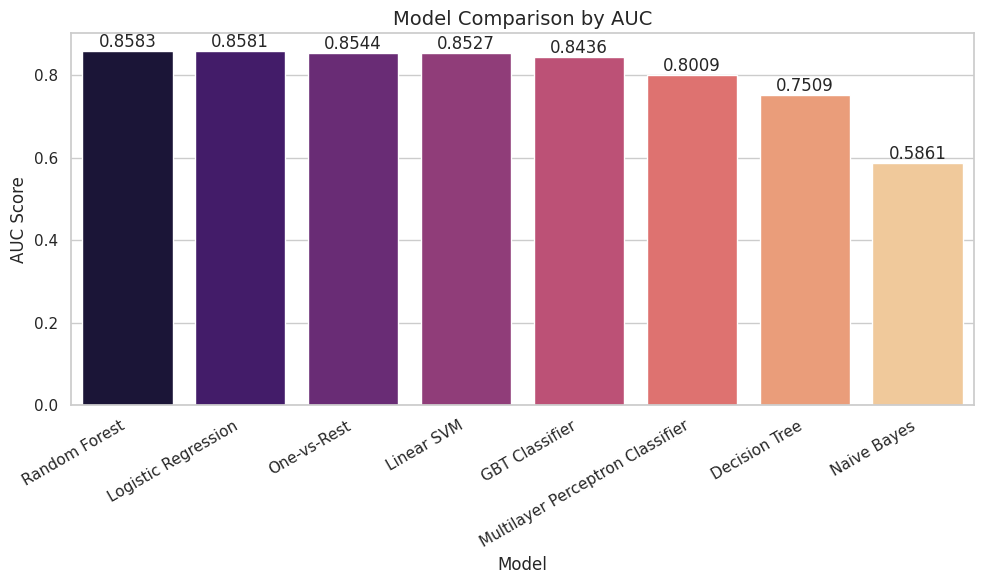

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Vẽ biểu đồ cột bằng Seaborn
ax = sns.barplot(
    data=results_pd,
    x="model",
    y="auc",
    palette="magma"
)

plt.title("Model Comparison by AUC", fontsize=14)
plt.xlabel("Model", fontsize=12)
plt.ylabel("AUC Score", fontsize=12)
plt.xticks(rotation=30, ha='right')

# Thêm nhãn giá trị lên đầu cột
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f')

plt.tight_layout()
plt.show()

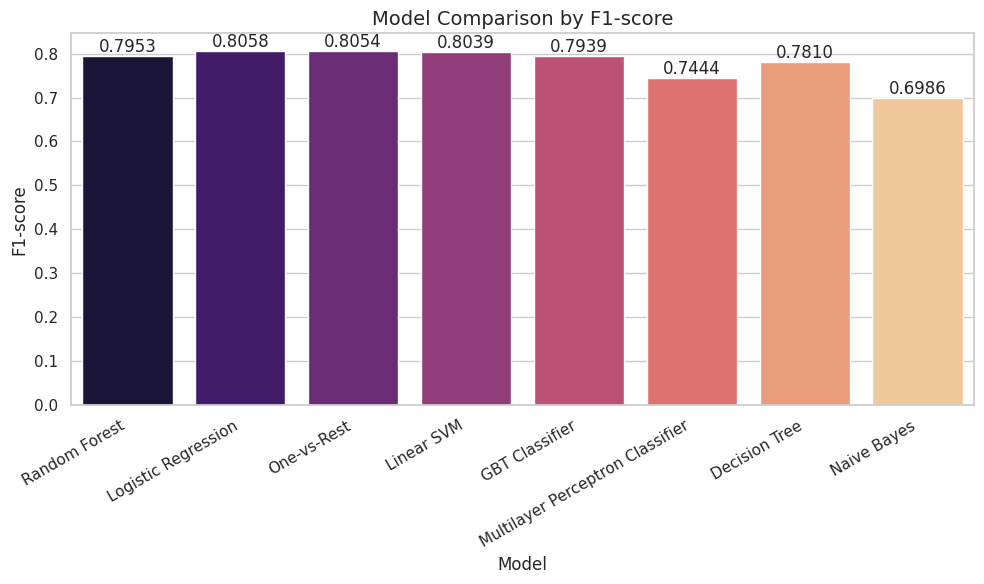

In [ ]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Vẽ biểu đồ cột bằng Seaborn
ax = sns.barplot(
    data=results_pd,
    x="model",
    y="f1",
    palette="magma"
)

plt.title("Model Comparison by F1-score", fontsize=14)
plt.xlabel("Model", fontsize=12)
plt.ylabel("F1-score", fontsize=12)
plt.xticks(rotation=30, ha='right')

# Thêm nhãn giá trị lên đầu cột
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f')

plt.tight_layout()
plt.show()

# 14.1. Hyperparameter Tuning for Random Forest

Phần này tối ưu Random Forest bằng `CrossValidator`.  
Để notebook chạy ổn trên Colab, lưới tham số được giữ ở mức vừa phải.


In [ ]:
rf_tune = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    seed=SEED
)

rf_tune_pipeline = Pipeline(stages=preprocess_stages + [rf_tune])

param_grid = (
    ParamGridBuilder()
    .addGrid(rf_tune.numTrees, [100, 200])
    .addGrid(rf_tune.maxDepth, [5, 10, 15])
    .build()
)

auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

cv = CrossValidator(
    estimator=rf_tune_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=auc_evaluator,
    numFolds=3,
    seed=SEED
)

cv_model = cv.fit(train_df)
best_rf_model = cv_model.bestModel

tuned_rf_pred = best_rf_model.transform(test_df)
tuned_rf_metrics = evaluate_predictions(tuned_rf_pred, "Tuned Random Forest")
model_results.append(tuned_rf_metrics)

tuned_rf_metrics

{'model': 'Tuned Random Forest',
 'accuracy': 0.8032786885245902,
 'precision': 0.7917533501590095,
 'recall': 0.8032786885245902,
 'f1': 0.7938027692641741,
 'auc': 0.8555041922388898}

In [ ]:
results_pd = pd.DataFrame(model_results).sort_values(by="auc", ascending=False).reset_index(drop=True)
results_pd

,model,accuracy,precision,recall,f1,auc
0,Random Forest,0.807750,0.795499,0.807750,0.795329,0.858271
1,Logistic Regression,0.810730,0.803400,0.810730,0.805831,0.858129
2,Tuned Random Forest,0.803279,0.791753,0.803279,0.793803,0.855504
3,One-vs-Rest,0.809985,0.802988,0.809985,0.805408,0.854420
4,Linear SVM,0.810730,0.801625,0.810730,0.803930,0.852727
5,GBT Classifier,0.800298,0.791040,0.800298,0.793893,0.843577
6,Multilayer Perceptron Classifier,0.762295,0.740363,0.762295,0.744431,0.800909
7,Decision Tree,0.790611,0.777919,0.790611,0.780967,0.750903
8,Naive Bayes,0.678838,0.759652,0.678838,0.698559,0.586073


# 14.2. Hyperparameter Tuning for Logistic Regression

Tối ưu hóa mô hình Logistic Regression bằng cách tìm kiếm trên lưới các tham số chính quy hóa.

In [ ]:
lr_tune = LogisticRegression(featuresCol="features", labelCol="label")

lr_tune_pipeline = Pipeline(stages=preprocess_stages + [lr_tune])

# Thiết lập lưới tham số
param_grid_lr = (
    ParamGridBuilder()
    .addGrid(lr_tune.regParam, [0.01, 0.1, 0.5])
    .addGrid(lr_tune.elasticNetParam, [0.0, 0.5, 1.0])
    .build()
)

# Sử dụng CrossValidator
cv_lr = CrossValidator(
    estimator=lr_tune_pipeline,
    estimatorParamMaps=param_grid_lr,
    evaluator=auc_evaluator,
    numFolds=3,
    seed=SEED
)

print("Đang huấn luyện và tối ưu Logistic Regression...")
cv_lr_model = cv_lr.fit(train_df)
best_lr_model = cv_lr_model.bestModel

# Dự đoán và đánh giá
tuned_lr_pred = best_lr_model.transform(test_df)
tuned_lr_metrics = evaluate_predictions(tuned_lr_pred, "Tuned Logistic Regression")
model_results.append(tuned_lr_metrics)

display(tuned_lr_metrics)

Đang huấn luyện và tối ưu Logistic Regression...


{'model': 'Tuned Logistic Regression',
 'accuracy': 0.8077496274217586,
 'precision': 0.7981861329436155,
 'recall': 0.8077496274217586,
 'f1': 0.8005907167924619,
 'auc': 0.8556617842332124}

In [ ]:
# Cập nhật lại bảng so sánh kết quả
results_pd = pd.DataFrame(model_results).sort_values(by="auc", ascending=False).reset_index(drop=True)
display(results_pd)

,model,accuracy,precision,recall,f1,auc
0,Random Forest,0.807750,0.795499,0.807750,0.795329,0.858271
1,Logistic Regression,0.810730,0.803400,0.810730,0.805831,0.858129
2,Tuned Logistic Regression,0.807750,0.798186,0.807750,0.800591,0.855662
3,Tuned Random Forest,0.803279,0.791753,0.803279,0.793803,0.855504
4,One-vs-Rest,0.809985,0.802988,0.809985,0.805408,0.854420
5,Linear SVM,0.810730,0.801625,0.810730,0.803930,0.852727
6,GBT Classifier,0.800298,0.791040,0.800298,0.793893,0.843577
7,Multilayer Perceptron Classifier,0.762295,0.740363,0.762295,0.744431,0.800909
8,Decision Tree,0.790611,0.777919,0.790611,0.780967,0.750903
9,Naive Bayes,0.678838,0.759652,0.678838,0.698559,0.586073


# 15. Confusion Matrix of the Best Model

In [ ]:
best_model_name = results_pd.iloc[0]["model"]
print("Best model:", best_model_name)

prediction_map = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "GBT Classifier": gbt_pred,
    "Tuned Random Forest": tuned_rf_pred,
    "Multilayer Perceptron Classifier": mlp_pred
}

best_pred = prediction_map[best_model_name]
show_confusion_matrix(best_pred)

Best model: Random Forest
+-----+---+---+
|label|0.0|1.0|
+-----+---+---+
|  0.0|922| 77|
|  1.0|181|162|
+-----+---+---+



# 16.1. Feature Importance (Gini Importance) for Random Forest


In [ ]:
# Dùng rf_model (mô hình gốc) để xem feature importance
rf_stage_model = rf_model.stages[-1]
transformed_train = rf_model.transform(train_df)

# Lấy tên features từ metadata
attrs = transformed_train.schema["features"].metadata["ml_attr"]["attrs"]
feature_names = []
for attr_type in attrs:
    feature_names.extend([x["name"] for x in attrs[attr_type]])

importances = rf_stage_model.featureImportances.toArray()

feature_importance_pd = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values(by="importance", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

feature_importance_pd

,feature,importance
0,tenure,0.169001
1,Contract_ohe_Month-to-month,0.123281
2,TotalCharges,0.103166
3,OnlineSecurity_ohe_No,0.066560
4,TechSupport_ohe_No,0.061399
5,MonthlyCharges,0.058828
6,InternetService_ohe_Fiber optic,0.056560
7,Contract_ohe_Two year,0.045283
8,PaymentMethod_ohe_Electronic check,0.039454
9,OnlineBackup_ohe_No,0.024459


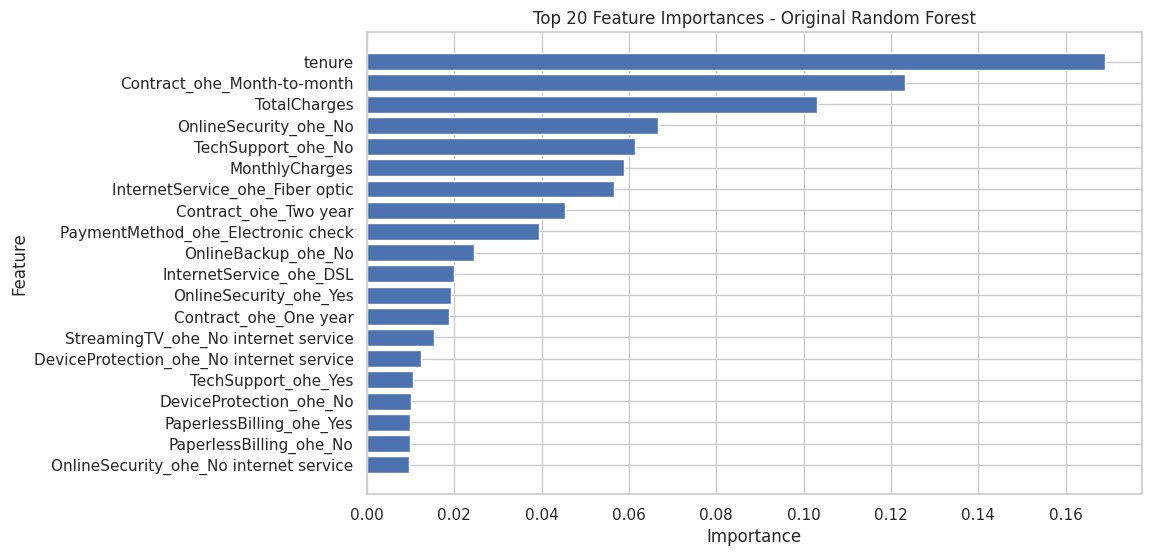

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_pd["feature"][::-1], feature_importance_pd["importance"][::-1])
plt.title("Top 20 Feature Importances - Original Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# 16.1. Feature Importance (Coefficients) for Logistic Regression

Đối với Logistic Regression, chúng ta xem xét các hệ số (coefficients) để hiểu mức độ ảnh hưởng của từng đặc trưng.

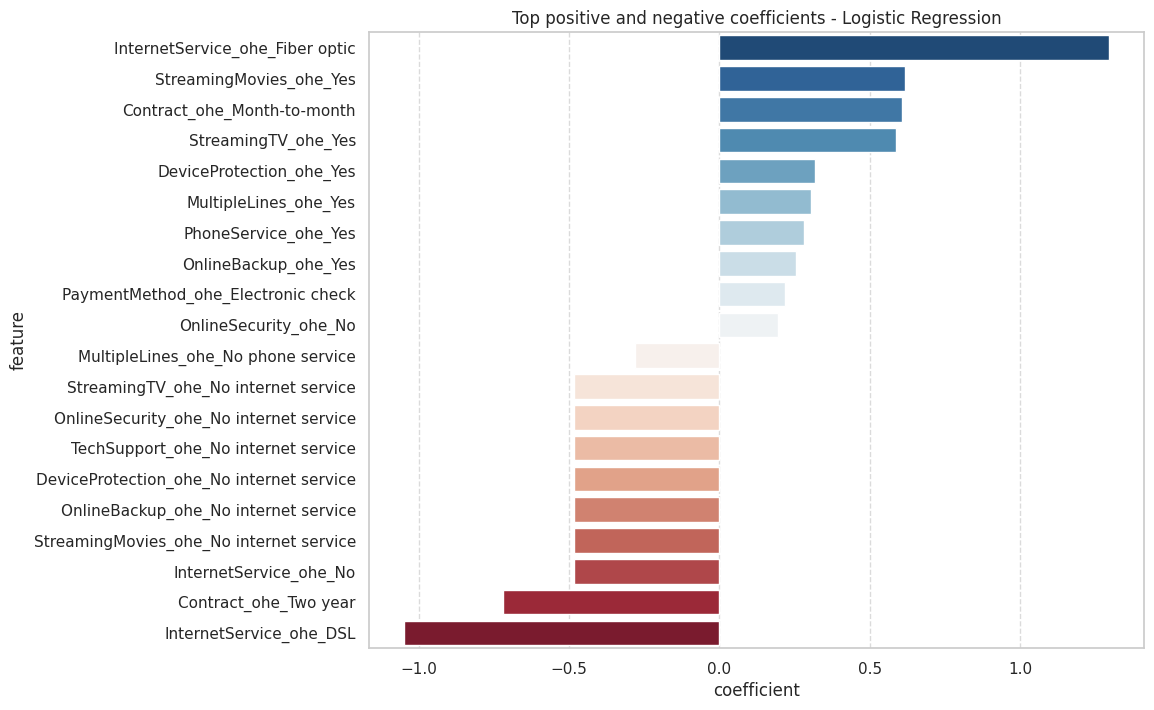

,feature,coefficient
11,InternetService_ohe_Fiber optic,1.294243
30,StreamingMovies_ohe_Yes,0.615838
32,Contract_ohe_Month-to-month,0.607858
27,StreamingTV_ohe_Yes,0.586331
21,DeviceProtection_ohe_Yes,0.318638
9,MultipleLines_ohe_Yes,0.303154
6,PhoneService_ohe_Yes,0.279985
18,OnlineBackup_ohe_Yes,0.254474
37,PaymentMethod_ohe_Electronic check,0.218926
14,OnlineSecurity_ohe_No,0.193405


In [ ]:
# Lấy mô hình Logistic Regression từ pipeline
lr_stage_model = lr_model.stages[-1]
weights = lr_stage_model.coefficients.toArray()

# Kết hợp với tên đặc trưng
lr_feature_importance_pd = pd.DataFrame({
    'feature': feature_names,
    'coefficient': weights
}).sort_values(by='coefficient', ascending=False)

# Trực quan hóa - Sử dụng pd.concat thay cho .append để tránh lỗi trên pandas mới
plt.figure(figsize=(10, 8))
top_bottom_features = pd.concat([lr_feature_importance_pd.head(10), lr_feature_importance_pd.tail(10)])

sns.barplot(data=top_bottom_features,
            x='coefficient', y='feature', palette='RdBu_r')
plt.title("Top positive and negative coefficients - Logistic Regression")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

display(lr_feature_importance_pd.head(10))

### So sánh Feature Importance: LR vs RF

- **Logistic Regression**: Cho thấy mối quan hệ tuyến tính và chiều hướng ảnh hưởng. Ví dụ: Dùng Fiber Optic (hệ số dương lớn) làm tăng nguy cơ churn mạnh nhất, trong khi hợp đồng 2 năm (hệ số âm lớn) giữ chân khách hàng tốt nhất.
- **Random Forest**: Tập trung vào khả năng phân tách dữ liệu. `tenure` đứng đầu cho thấy thời gian sử dụng dịch vụ là yếu tố phân loại khách hàng tốt nhất.
- **Sự khác biệt**: RF đánh giá cao `TotalCharges` hơn LR. Điều này có thể do quan hệ giữa chi phí và churn không hoàn toàn là tuyến tính, mà RF (mô hình phi tuyến) bắt bài tốt hơn.

# 17. Save the Best Model

In [ ]:
BEST_MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/Churn_Prediction/best_churn_model"
rf_model.write().overwrite().save(BEST_MODEL_PATH)
print("Model saved to:", BEST_MODEL_PATH)

Model saved to: /content/drive/MyDrive/Colab Notebooks/Churn_Prediction/best_churn_model


# 18. Demo Prediction on New Customer Samples

In [ ]:
sample_data = [
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "No",
        "tenure": 5,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "Yes",
        "StreamingMovies": "Yes",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 85.5,
        "TotalCharges": 427.5
    },
    {
        "gender": "Male",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "Yes",
        "tenure": 60,
        "PhoneService": "Yes",
        "MultipleLines": "Yes",
        "InternetService": "DSL",
        "OnlineSecurity": "Yes",
        "OnlineBackup": "Yes",
        "DeviceProtection": "Yes",
        "TechSupport": "Yes",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Two year",
        "PaperlessBilling": "No",
        "PaymentMethod": "Bank transfer (automatic)",
        "MonthlyCharges": 64.9,
        "TotalCharges": 3894.0
    }
]

sample_pd = pd.DataFrame(sample_data)
sample_spark = spark.createDataFrame(sample_pd)

print("--- Predictions using Best Model (Random Forest) ---")
sample_pred_rf = best_rf_model.transform(sample_spark)
sample_pred_rf.select("prediction", "probability").show(truncate=False)

print("--- Predictions using Logistic Regression ---")
sample_pred_lr = lr_model.transform(sample_spark)
sample_pred_lr.select("prediction", "probability").show(truncate=False)

--- Predictions using Best Model (Random Forest) ---
+----------+-----------------------------------------+
|prediction|probability                              |
+----------+-----------------------------------------+
|1.0       |[0.2487787464409805,0.7512212535590195]  |
|0.0       |[0.9832929269772411,0.016707073022758805]|
+----------+-----------------------------------------+

--- Predictions using Logistic Regression ---
+----------+----------------------------------------+
|prediction|probability                             |
+----------+----------------------------------------+
|1.0       |[0.19602542695582903,0.803974573044171] |
|0.0       |[0.990196167578977,0.009803832421023007]|
+----------+----------------------------------------+



# 19. Conclusion

## Kết quả đạt được
- Xây dựng pipeline tiền xử lý dữ liệu bằng PySpark
- Phân tích dữ liệu bằng SparkSQL
- Huấn luyện và so sánh nhiều mô hình Spark ML
- Tối ưu Random Forest bằng CrossValidator
- Trích xuất các đặc trưng quan trọng

## Hướng phát triển
- Thử thêm xử lý mất cân bằng dữ liệu
- So sánh với mô hình deep learning ngoài Spark
- Đưa mô hình vào dashboard hoặc API


In [ ]:
# Khi hoàn tất có thể dừng Spark
spark.stop()
print("Spark stopped!")

Spark stopped!
